# Jagran Lakecity University
## Faculty of Science and Technology
### BTech CSE

---

## Practical Record: Assignment 3 - Module 3
### **Practical 9: Differential Evolution (DE)**

| Academic Details | Information |
| :--- | :--- |
| **Course** | Soft Computing |
| **Module** | Module III: Genetic Algorithms and Evolutionary Computing |
| **Student Name** | *Yashvi Shivhare* |
| **Enrollment No.** | *2023BTCSE021* |
| **Academic Session** | 2026 – 2027 |

---

### 1. Aim
To implement a simple Differential Evolution (DE) algorithm for solving an optimization problem using Python.

### 2. Theory: DE/rand/1/bin Strategy

Differential Evolution perturbs vectors using scaled differences of randomly sampled population members:
$$\mathbf{v}_i = \mathbf{x}_{r1} + F(\mathbf{x}_{r2} - \mathbf{x}_{r3})$$
followed by binomial crossover ($CR$) and greedy selection.

### 3. Step 1: Minimizing Rastrigin Function with DE

Best Solution: [4.e-06 5.e-06], Best Cost: 0.00000001


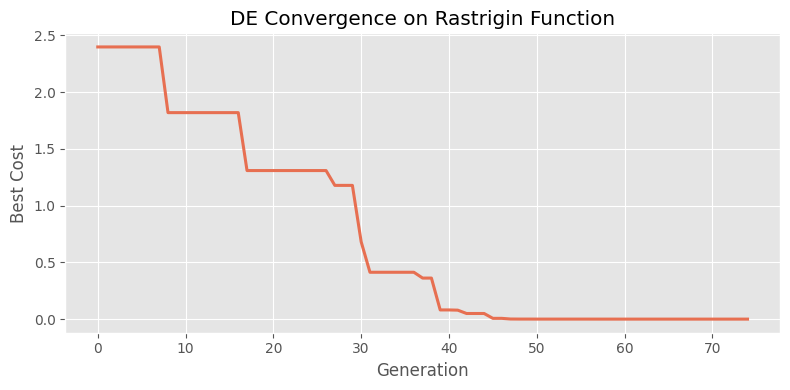

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(909)
plt.style.use('ggplot')

def rastrigin(x):
    return 10 * len(x) + np.sum(x**2 - 10 * np.cos(2 * np.pi * x))

pop_size, dim, gens = 35, 2, 75
F, CR = 0.75, 0.8
low, high = -5.12, 5.12

pop = np.random.uniform(low, high, (pop_size, dim))
fit = np.array([rastrigin(ind) for ind in pop])
hist = []

for _ in range(gens):
    for i in range(pop_size):
        pool = [j for j in range(pop_size) if j != i]
        r1, r2, r3 = pop[np.random.choice(pool, 3, replace=False)]
        mutant = np.clip(r1 + F * (r2 - r3), low, high)
        j_rand = np.random.randint(dim)
        mask = (np.random.rand(dim) < CR) | (np.arange(dim) == j_rand)
        trial = np.where(mask, mutant, pop[i])
        f_t = rastrigin(trial)
        if f_t <= fit[i]:
            pop[i], fit[i] = trial, f_t
    hist.append(np.min(fit))

best = pop[np.argmin(fit)]
print(f"Best Solution: {np.round(best, 6)}, Best Cost: {np.min(fit):.8f}")

plt.figure(figsize=(8, 4))
plt.plot(hist, color='#e76f51', linewidth=2.2)
plt.title("DE Convergence on Rastrigin Function")
plt.xlabel("Generation")
plt.ylabel("Best Cost")
plt.tight_layout()
plt.show()

### 4. Conclusion
Differential Evolution (`DE/rand/1/bin`) escaped local minima and converged to the global optimum of the Rastrigin function.